# Eksploracja danych  - PS 3 - Tomasz Jarmoc i Krzysztof Sobolewski


Dla zbioru danych użytego w raporcie 3 (do klasyfikacji) przeprowadź analizę skupień wyłączając kolumnę ze zmienną zależną (lub etykietami klasy, jeśli to zbiór do klasyfikacji). W drugim przypadku użyj kolumny z etykietami klasy do sprawdzenia jakości uzyskanych klastrów.

Użyj:

- metod hierarchicznych (z 3 różnymi sposobami liczenia odległości między klastrami) - sporządź dendrogram dla każdej z metod
- metody k-średnich
- metody EM
- metody DBSCAN
- jednej innej - dowolnej metody

Porównaj uzyskane wyniki - liczbę uzyskanych klastrów i ich jakość.
Dla tego zbioru zmienna zależna to `charges`, więc nie bierzemy jej do grupowania. Ponieważ jest ciągła, porównujemy klastry z `charges` przez R2 liczone na podstawie średniej wartości w klastrze; nie stosujemy ARI ani NMI.


In [1]:
import os
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, Birch, DBSCAN, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.mixture import GaussianMixture
from sklearn.metrics import r2_score, silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plik_csv = 'insurance.csv'
link_do_pliku = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
if not os.path.exists(plik_csv):
    urlretrieve(link_do_pliku, plik_csv)

df = pd.read_csv(plik_csv)
print(f'Wymiary danych: {df.shape}')
display(df.head())


Wymiary danych: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# Zmienna zalezna charges jest wylaczona z cech klasteryzacji.
y = df['charges']
X = df.drop(columns='charges')
kolumny_numeryczne = X.select_dtypes(include=np.number).columns.tolist()
kolumny_kategoryczne = X.select_dtypes(exclude=np.number).columns.tolist()

przetwarzanie = ColumnTransformer(transformers=[
    ('num', StandardScaler(), kolumny_numeryczne),
    ('kat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kolumny_kategoryczne),
])
X_scaled = przetwarzanie.fit_transform(X)
print(f'Liczba cech po kodowaniu: {X_scaled.shape[1]}')


Liczba cech po kodowaniu: 11


## 1. Metody hierarchiczne

Ponizej porownujemy dendrogramy dla metod Ward, complete i average. Dla czytelnosci pokazane jest ostatnie 30 polaczen.

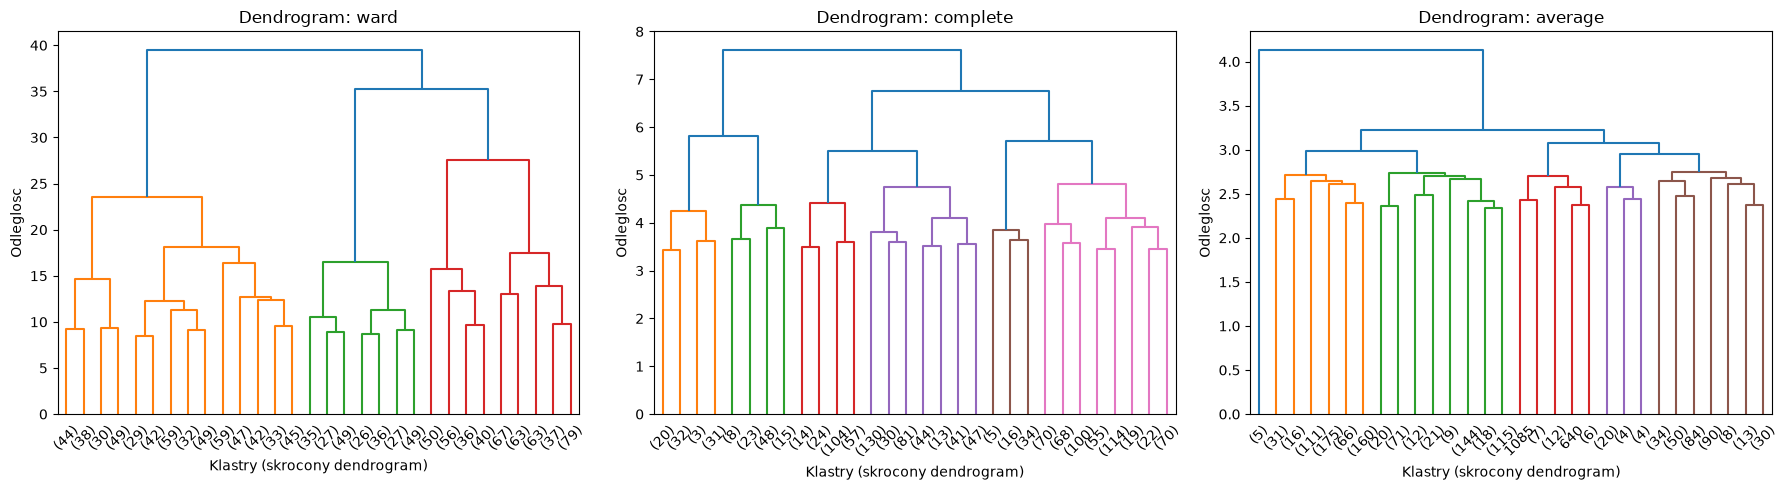

In [3]:
metody_linkage = ['ward', 'complete', 'average']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metoda in zip(axes, metody_linkage):
    Z = linkage(X_scaled, method=metoda, metric='euclidean')
    dendrogram(Z, truncate_mode='lastp', p=30, ax=ax)
    ax.set_title(f'Dendrogram: {metoda}')
    ax.set_xlabel('Klastry (skrocony dendrogram)')
    ax.set_ylabel('Odleglosc')

plt.tight_layout()
display(fig)
plt.close(fig)


## 2. DBSCAN - dobor parametrow

DBSCAN laczy punkty z gestych obszarow w klastry, a punkty odosobnione oznacza jako szum (-1). Parametry: `eps` (promien sasiedztwa) i `min_samples` (minimalna liczba sasiadow punktu rdzeniowego). Przyjmujemy `min_samples = 6` (2 x 3 cechy numeryczne). `eps` musi byc mniejsze od sqrt(2) = 1.414 - tyle wynosi minimalna odleglosc miedzy roznymi kombinacjami cech one-hot.

In [4]:
from sklearn.neighbors import NearestNeighbors


def ocen_podzial(etykiety):
    maska = etykiety != -1
    etykiety_bez_szumu = etykiety[maska]
    charges_w_klastrach = y.to_numpy()[maska]
    srednie_charges = pd.Series(charges_w_klastrach).groupby(etykiety_bez_szumu).transform('mean')
    return {
        'Liczba klastrow': len(np.unique(etykiety_bez_szumu)),
        'Szum (DBSCAN)': int((~maska).sum()),
        'Silhouette': silhouette_score(
            X_scaled[maska], etykiety_bez_szumu,
            sample_size=min(1000, int(maska.sum())), random_state=42,
        ),
        'R2 wzgledem charges': r2_score(charges_w_klastrach, srednie_charges),
    }


def profil_klastrow(etykiety):
    dane = df.assign(palacz=df['smoker'].eq('yes'), mezczyzna=df['sex'].eq('male'))
    return dane.groupby(etykiety).agg(**{
        'Licznosc': ('charges', 'size'),
        'Srednie charges': ('charges', 'mean'),
        'Sredni wiek': ('age', 'mean'),
        'Srednie BMI': ('bmi', 'mean'),
        'Srednia liczba dzieci': ('children', 'mean'),
        'Udzial palacych': ('palacz', 'mean'),
        'Udzial mezczyzn': ('mezczyzna', 'mean'),
        'Najczestszy region': ('region', lambda s: s.value_counts().index[0]),
        'Udzial tego regionu': ('region', lambda s: s.value_counts(normalize=True).iloc[0]),
    }).rename_axis('Klaster')

Percentyle odleglosci do 6. sasiada (50/75/90/95%): [0.831 1.01  1.334 1.478]
Odsetek punktow rdzeniowych przy eps = 1.4: 0.913


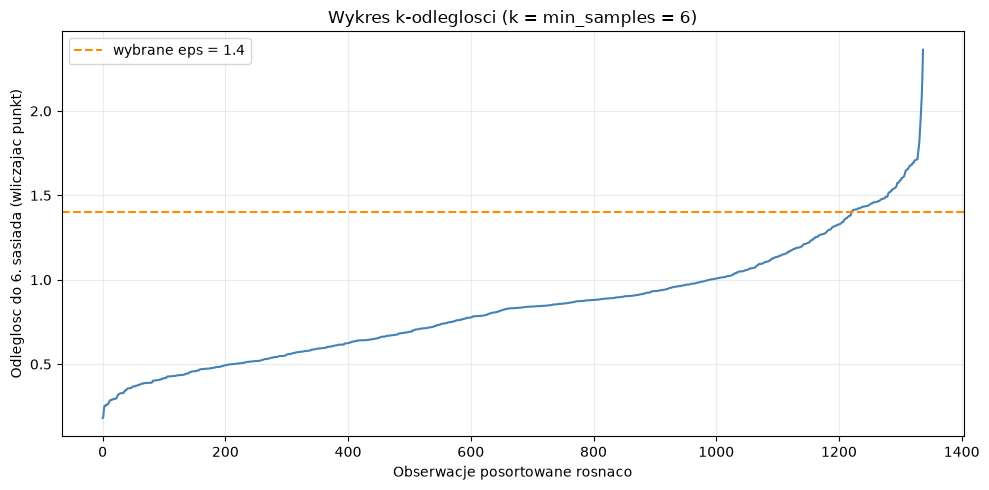

In [5]:
min_samples_dbscan = 6
eps_dbscan = 1.4

sasiedzi = NearestNeighbors(n_neighbors=min_samples_dbscan).fit(X_scaled)
odleglosci, _ = sasiedzi.kneighbors(X_scaled)
odleglosci_k = np.sort(odleglosci[:, -1])
print(f'Percentyle odleglosci do {min_samples_dbscan}. sasiada (50/75/90/95%): {np.percentile(odleglosci_k, [50, 75, 90, 95]).round(3)}')
print(f'Odsetek punktow rdzeniowych przy eps = {eps_dbscan}: {(odleglosci_k <= eps_dbscan).mean():.3f}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(odleglosci_k, color='steelblue')
ax.axhline(eps_dbscan, color='darkorange', linestyle='--', label=f'wybrane eps = {eps_dbscan}')
ax.set_title(f'Wykres k-odleglosci (k = min_samples = {min_samples_dbscan})')
ax.set_xlabel('Obserwacje posortowane rosnaco')
ax.set_ylabel(f'Odleglosc do {min_samples_dbscan}. sasiada (wliczajac punkt)')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
display(fig)
plt.close(fig)

### Przeglad parametrow DBSCAN

Silhouette i R2 liczone bez szumu, tak jak w sekcji 5.

In [6]:
wartosci_eps = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4]
przeglad_eps = pd.DataFrame([
    {'eps': eps, **ocen_podzial(DBSCAN(eps=eps, min_samples=min_samples_dbscan).fit_predict(X_scaled))}
    for eps in wartosci_eps
]).set_index('eps')
print(f'Przeglad eps dla min_samples = {min_samples_dbscan}:')
display(przeglad_eps.round(3))

wartosci_min_samples = [4, 6, 10, 15, 22]
przeglad_min_samples = pd.DataFrame([
    {'min_samples': ms, **ocen_podzial(DBSCAN(eps=eps_dbscan, min_samples=ms).fit_predict(X_scaled))}
    for ms in wartosci_min_samples
]).set_index('min_samples')
print(f'Przeglad min_samples dla eps = {eps_dbscan}:')
display(przeglad_min_samples.round(3))

etykiety_eps_15 = DBSCAN(eps=1.5, min_samples=min_samples_dbscan).fit_predict(X_scaled)
print(f'Kontrola eps = 1.5: liczba klastrow = {etykiety_eps_15.max() + 1}, szum = {(etykiety_eps_15 == -1).sum()}')

Przeglad eps dla min_samples = 6:


,Liczba klastrow,Szum (DBSCAN),Silhouette,R2 wzgledem charges
eps,,,,
0.5,32,940,0.520,0.649
0.6,40,758,0.392,0.699
0.7,37,640,0.221,0.621
0.8,39,487,0.126,0.536
0.9,17,276,0.076,0.547
1.0,17,186,0.096,0.595
1.1,19,119,0.074,0.611
1.2,18,88,0.087,0.618
1.3,17,57,0.104,0.613


Przeglad min_samples dla eps = 1.4:


,Liczba klastrow,Szum (DBSCAN),Silhouette,R2 wzgledem charges
min_samples,,,,
4,16,15,0.131,0.627
6,16,40,0.120,0.618
10,15,112,0.113,0.618
15,12,197,0.144,0.567
22,8,319,0.160,0.010


Kontrola eps = 1.5: liczba klastrow = 1, szum = 8


### Model koncowy DBSCAN

Wybieramy `eps = 1.4` i `min_samples = 6`: najmniej szumu (40 punktow) ponizej progu 1.414. Dla `eps = 1.5` powstaje 1 klaster, a dla `min_samples >= 10` male grupy palaczy trafiaja do szumu.

In [7]:
etykiety_dbscan = DBSCAN(eps=eps_dbscan, min_samples=min_samples_dbscan).fit_predict(X_scaled)
display(pd.DataFrame([ocen_podzial(etykiety_dbscan)], index=['DBSCAN']).round(3))

profil_dbscan = profil_klastrow(etykiety_dbscan)
display(profil_dbscan.sort_values('Srednie charges', ascending=False).round(3))

kombinacje_w_klastrach = df.groupby(etykiety_dbscan)[['sex', 'smoker', 'region']].nunique().drop(index=-1)
print(f'Klastry jednorodne pod wzgledem sex, smoker i region: {(kombinacje_w_klastrach.max(axis=1) == 1).sum()} z {len(kombinacje_w_klastrach)}')
srednie_wg_smoker = y.groupby(df['smoker']).transform('mean')
print(f'Dla porownania: R2 dla podzialu tylko wedlug smoker = {r2_score(y, srednie_wg_smoker):.3f}')

,Liczba klastrow,Szum (DBSCAN),Silhouette,R2 wzgledem charges
DBSCAN,16,40,0.12,0.618


,Licznosc,Srednie charges,Sredni wiek,Srednie BMI,Srednia liczba dzieci,Udzial palacych,Udzial mezczyzn,Najczestszy region,Udzial tego regionu
Klaster,,,,,,,,,
8,53,35755.236,40.679,33.068,1.019,1.0,1.0,southeast,1.000
10,35,32633.253,34.800,31.611,1.371,1.0,1.0,southwest,1.000
-1,40,32186.537,43.150,35.156,2.300,0.8,0.3,southwest,0.375
6,30,31409.510,37.767,31.412,0.667,1.0,0.0,southeast,1.000
14,29,30713.181,39.828,29.984,1.724,1.0,1.0,northwest,1.000
13,35,30573.304,38.029,29.244,0.743,1.0,1.0,northeast,1.000
15,27,29532.296,38.741,28.285,0.667,1.0,0.0,northwest,1.000
0,10,26712.093,26.300,28.540,0.100,1.0,0.0,southwest,1.000
12,23,24138.753,35.435,24.997,1.217,1.0,0.0,northeast,1.000


Klastry jednorodne pod wzgledem sex, smoker i region: 16 z 16
Dla porownania: R2 dla podzialu tylko wedlug smoker = 0.620


### Wnioski - DBSCAN

- 16 klastrow, 40 punktow szumu (3%), Silhouette 0.120, R2 wzgledem `charges` 0.618.
- Kazdy klaster to jedna kombinacja `sex` x `smoker` x `region`.
- Srednie `charges`: klastry palaczy 24139-35755, klastry niepalacych 7596-9642.
- Szum to w 80% palacze.

## 3. Birch - dobor parametrow

Birch buduje drzewo CF z podklastrow o promieniu nie wiekszym niz `threshold`, a nastepnie laczy je w `n_clusters` klastrow. Sprawdzamy `threshold` od 0.5 do 1.2 i `n_clusters` od 2 do 8; wybieramy wariant z najwyzszym Silhouette.

In [8]:
progi_birch = [0.5, 0.8, 1.0, 1.2]
wiersze_birch = []
for prog in progi_birch:
    for k in range(2, 9):
        model = Birch(threshold=prog, n_clusters=k).fit(X_scaled)
        wiersze_birch.append({
            'threshold': prog,
            'k': k,
            'Podklastry CF': len(model.subcluster_centers_),
            **ocen_podzial(model.labels_),
        })
przeglad_birch = pd.DataFrame(wiersze_birch)

print('Liczba podklastrow CF dla kolejnych progow:')
display(przeglad_birch.groupby('threshold')['Podklastry CF'].first().to_frame())
print('Silhouette (wiersze: k, kolumny: threshold):')
display(przeglad_birch.pivot(index='k', columns='threshold', values='Silhouette').round(3))
print('R2 wzgledem charges (wiersze: k, kolumny: threshold):')
display(przeglad_birch.pivot(index='k', columns='threshold', values='R2 wzgledem charges').round(3))
print('5 wariantow z najwyzszym Silhouette:')
display(przeglad_birch.sort_values('Silhouette', ascending=False).head(5).round(3))

Liczba podklastrow CF dla kolejnych progow:


,Podklastry CF
threshold,
0.5,496
0.8,248
1.0,167
1.2,84


Silhouette (wiersze: k, kolumny: threshold):


threshold,0.5,0.8,1.0,1.2
k,,,,
2,0.108,0.136,0.118,0.134
3,0.098,0.117,0.098,0.118
4,0.122,0.131,0.087,0.117
5,0.111,0.112,0.085,0.103
6,0.112,0.094,0.078,0.109
7,0.095,0.093,0.089,0.106
8,0.090,0.091,0.088,0.098


R2 wzgledem charges (wiersze: k, kolumny: threshold):


threshold,0.5,0.8,1.0,1.2
k,,,,
2,0.005,0.000,0.001,0.000
3,0.026,0.001,0.071,0.000
4,0.032,0.020,0.071,0.094
5,0.060,0.021,0.079,0.100
6,0.281,0.044,0.080,0.227
7,0.291,0.048,0.083,0.246
8,0.292,0.224,0.085,0.246


5 wariantow z najwyzszym Silhouette:


,threshold,k,Podklastry CF,Liczba klastrow,Szum (DBSCAN),Silhouette,R2 wzgledem charges
7,0.8,2,248,2,0,0.136,0.000
21,1.2,2,84,2,0,0.134,0.000
9,0.8,4,248,4,0,0.131,0.020
2,0.5,4,496,4,0,0.122,0.032
14,1.0,2,167,2,0,0.118,0.001


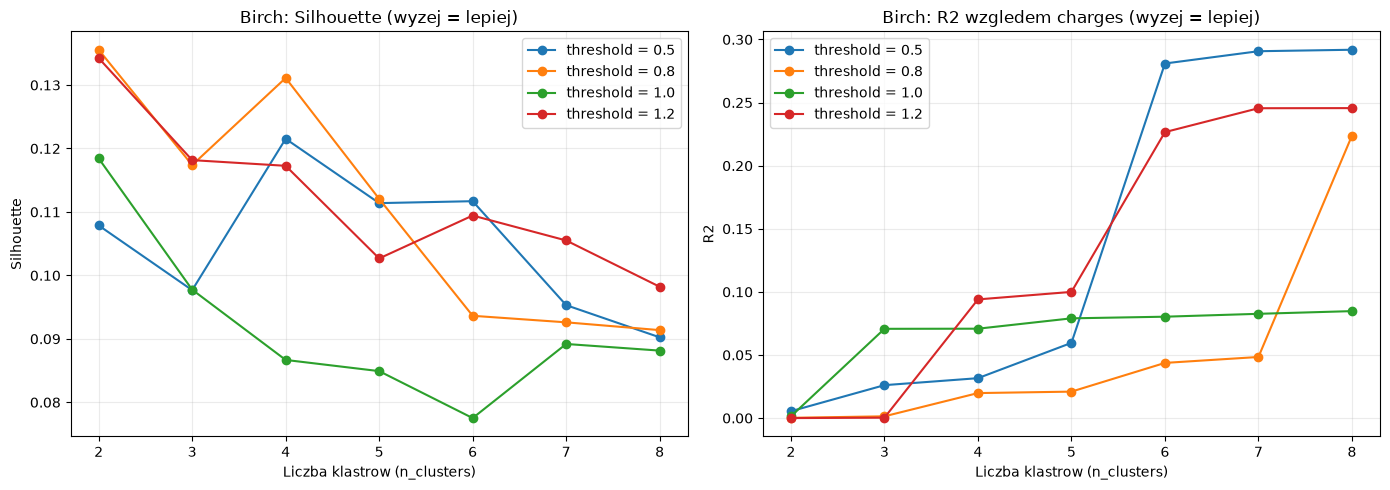

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for prog, grupa in przeglad_birch.groupby('threshold'):
    axes[0].plot(grupa['k'], grupa['Silhouette'], marker='o', label=f'threshold = {prog}')
    axes[1].plot(grupa['k'], grupa['R2 wzgledem charges'], marker='o', label=f'threshold = {prog}')

axes[0].set_title('Birch: Silhouette (wyzej = lepiej)')
axes[0].set_ylabel('Silhouette')
axes[1].set_title('Birch: R2 wzgledem charges (wyzej = lepiej)')
axes[1].set_ylabel('R2')

for ax in axes:
    ax.set_xlabel('Liczba klastrow (n_clusters)')
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
display(fig)
plt.close(fig)

### Wybor wariantu Birch

Najwyzszy Silhouette (0.136) daje `threshold = 0.8` i `n_clusters = 2`, co jest zgodne z k=2 z sekcji 4.

In [10]:
threshold_birch = 0.8
k_birch = 2

model_birch = Birch(threshold=threshold_birch, n_clusters=k_birch).fit(X_scaled)
etykiety_birch = model_birch.labels_
print(f'Liczba podklastrow CF: {len(model_birch.subcluster_centers_)}')
display(pd.DataFrame([ocen_podzial(etykiety_birch)], index=['Birch']).round(3))
display(profil_klastrow(etykiety_birch).round(3))
display(pd.crosstab(etykiety_birch, df['children'], rownames=['Klaster'], colnames=['children']))

Liczba podklastrow CF: 248


,Liczba klastrow,Szum (DBSCAN),Silhouette,R2 wzgledem charges
Birch,2,0,0.136,0.0


,Licznosc,Srednie charges,Sredni wiek,Srednie BMI,Srednia liczba dzieci,Udzial palacych,Udzial mezczyzn,Najczestszy region,Udzial tego regionu
Klaster,,,,,,,,,
0,933,13153.240,38.493,31.026,0.471,0.214,0.496,southeast,0.304
1,405,13540.376,40.852,29.828,2.533,0.183,0.526,northwest,0.326


children,0,1,2,3,4,5
Klaster,,,,,,
0,570,296,58,9,0,0
1,4,28,182,148,25,18


### Wnioski - Birch

- 2 klastry (933 i 405 obserwacji), Silhouette 0.136, R2 wzgledem `charges` 0.000.
- Podzial wedlug liczby dzieci (srednio 0.47 vs 2.53); udzial palacych i srednie `charges` w obu klastrach prawie rowne.
- Silhouette w calej siatce 0.078-0.136 - brak wyraznie odseparowanych grup.

## 4. Pozostale metody klasteryzacji

Dla porownywalnosci ustalamy k=2 w metodach wymagajacych liczby klastrow. DBSCAN sam wyznacza klastry; etykieta -1 oznacza szum. Parametry DBSCAN (`eps = 1.4`, `min_samples = 6`) i Birch (`threshold = 0.8`, `n_clusters = 2`) pochodza z doboru w sekcjach 2 i 3.

In [11]:
wyniki = {}

for metoda in metody_linkage:
    model = AgglomerativeClustering(n_clusters=2, linkage=metoda)
    wyniki[f'HAC ({metoda})'] = model.fit_predict(X_scaled)

wyniki['K-srednich'] = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_scaled)
wyniki['EM (Gaussian Mixture)'] = GaussianMixture(n_components=2, random_state=42).fit_predict(X_scaled)
wyniki['DBSCAN'] = DBSCAN(eps=eps_dbscan, min_samples=min_samples_dbscan).fit_predict(X_scaled)
wyniki['Birch'] = Birch(threshold=threshold_birch, n_clusters=k_birch).fit_predict(X_scaled)

print(f'Uruchomiono {len(wyniki)} wariantow klasteryzacji.')


Uruchomiono 7 wariantow klasteryzacji.


## 5. Porownanie jakosci

Silhouette ocenia spojnosc i separacje klastrow. R2 pokazuje, jaka czesc zroznicowania `charges` jest opisana przez srednie wartosci tej zmiennej w klastrach. Dla DBSCAN obserwacje szumowe sa pomijane w obu metrykach.


In [12]:
wiersze = []
for nazwa, etykiety in wyniki.items():
    maska = etykiety != -1
    etykiety_bez_szumu = etykiety[maska]
    klastry = np.unique(etykiety_bez_szumu)

    silhouette = np.nan
    if len(klastry) >= 2 and maska.sum() > len(klastry):
        silhouette = silhouette_score(
            X_scaled[maska], etykiety_bez_szumu,
            sample_size=min(1000, int(maska.sum())), random_state=42,
        )

    charges_r2 = np.nan
    if maska.sum() > 0:
        charges_w_klastrach = y.to_numpy()[maska]
        srednie_charges = pd.Series(charges_w_klastrach).groupby(etykiety_bez_szumu).transform('mean')
        charges_r2 = r2_score(charges_w_klastrach, srednie_charges)

    wiersze.append({
        'Metoda': nazwa,
        'Liczba klastrow': len(klastry),
        'Szum (DBSCAN)': int((etykiety == -1).sum()),
        'Silhouette': silhouette,
        'R2 wzgledem charges': charges_r2,
    })

porownanie = pd.DataFrame(wiersze).set_index('Metoda')
display(porownanie.round(3))


,Liczba klastrow,Szum (DBSCAN),Silhouette,R2 wzgledem charges
Metoda,,,,
HAC (ward),2,0,0.117,0.014
HAC (complete),2,0,0.146,0.002
HAC (average),2,0,0.270,0.001
K-srednich,2,0,0.161,0.064
EM (Gaussian Mixture),2,0,0.115,0.620
DBSCAN,16,40,0.120,0.618
Birch,2,0,0.136,0.000


## 6. Wykresy porownawcze

Wykresy pokazuja liczbe klastrow, Silhouette oraz R2 wzgledem zmiennej zaleznej `charges`.


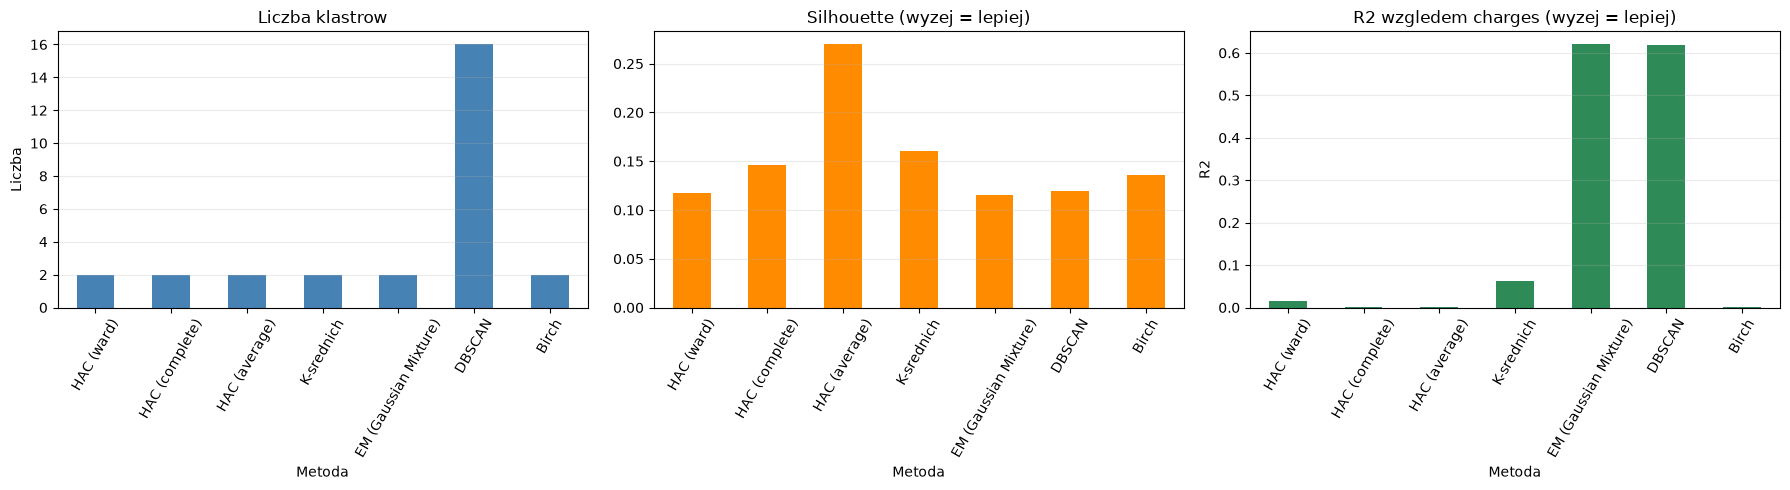

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

porownanie['Liczba klastrow'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Liczba klastrow')
axes[0].set_ylabel('Liczba')

porownanie['Silhouette'].dropna().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Silhouette (wyzej = lepiej)')

porownanie['R2 wzgledem charges'].plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('R2 wzgledem charges (wyzej = lepiej)')
axes[2].set_ylabel('R2')

for ax in axes:
    ax.tick_params(axis='x', labelrotation=60)
    ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
display(fig)
plt.close(fig)
